# Bayesian Media Mix Model with PyMC

**Goal:** estimate how much revenue each of the 7 paid channels brings, including the delayed effect of spend, and get a ROI estimate per channel.

**Model in one line:** weekly revenue = baseline (intercept + linear trend + yearly seasonality + Cyber Week) + sum over channels of ROAS × adstocked spend + Normal noise. Carry-over is a geometric adstock with one decay rate per channel. As suggested in the README, there is no saturation.

**Structure**
1. Data and first look
2. Features
3. Carry-over (adstock)
4. Model and priors
5. Prior predictive check
6. Sampling and diagnostics
7. Prior vs posterior
8. Model performance
9. Channel insights
10. ROI per channel
11. Summary and limitations

The README questions are answered in the PDF report. All numbers come from one run with `SEED = 42`. On another machine the last digits can change slightly, because floating-point results differ between machines.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pymc as pm

warnings.filterwarnings("ignore", category=FutureWarning)  # ArviZ prints a notice about its upcoming refactor
import arviz as az

SEED = 42
DATA_PATH = "MMM_test_data.csv"
rng = np.random.default_rng(SEED)
CORES = min(4, os.cpu_count() or 1)
plt.rcParams["figure.figsize"] = (11, 3.5)
print("PyMC", pm.__version__, "| ArviZ", az.__version__)

PyMC 5.28.5 | ArviZ 0.23.4


## 1. Data and first look

I load the data and check each channel: its share of the budget, how often it is switched off, and its raw correlation with revenue.

In [2]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["start_of_week"], format="%d-%m-%y")  # dates are day-month-year

channels = [f"spend_channel_{i}" for i in range(1, 8)]
ch_names = [f"ch{i}" for i in range(1, 8)]
spend = df[channels].values          # weeks x channels, in €
T, C = spend.shape
print(f"{T} weeks: {df.date.min().date()} to {df.date.max().date()}")
print(f"Total spend / total revenue = {spend.sum() / df.revenue.sum():.0%}")

overview = pd.DataFrame({
    "total_spend_€": spend.sum(0).round(0),
    "share_of_spend_%": (100 * spend.sum(0) / spend.sum()).round(1),
    "weeks_with_zero_spend_%": (100 * (spend == 0).mean(0)).round(1),
    "corr_with_revenue": df[channels].corrwith(df["revenue"]).values.round(2),
}, index=ch_names)
overview

104 weeks: 2020-08-30 to 2022-08-21
Total spend / total revenue = 51%


,total_spend_€,share_of_spend_%,weeks_with_zero_spend_%,corr_with_revenue
ch1,129543.0,1.8,12.5,0.32
ch2,35739.0,0.5,0.0,0.08
ch3,2028747.0,28.1,0.0,0.38
ch4,719174.0,10.0,0.0,0.26
ch5,891864.0,12.4,0.0,0.42
ch6,526625.0,7.3,37.5,0.52
ch7,2880942.0,39.9,0.0,0.25


- ch7 and ch3 take about 68% of the budget. ch2 has only 0.5%, so the model will not learn much about it.
- ch1 and ch6 are switched off in some weeks. This on/off variation helps the model to see their effect.
- Total spend is about half of revenue. I use this when I set the ROAS prior.
- The raw correlations ignore the delay and the other channels, so they are only a first hint.

Next I check how much the channels move together. If two channels always change together, the model cannot separate their effects.

In [3]:
corr_mat = np.corrcoef(spend.T)
iu = np.triu_indices(C, k=1)   # each pair once (21 pairs)
pair_corr = pd.Series(corr_mat[iu], index=[f"{ch_names[i]} & {ch_names[j]}" for i, j in zip(*iu)]).sort_values(ascending=False)
print("Most correlated pairs:")
print(pair_corr.head(3).round(2).to_string())
print(f"\nMedian over all 21 pairs: {pair_corr.median():.2f}  |  range: {pair_corr.min():.2f} to {pair_corr.max():.2f}")

Most correlated pairs:
ch5 & ch6    0.65
ch2 & ch7    0.59
ch4 & ch7    0.56

Median over all 21 pairs: 0.28  |  range: -0.31 to 0.65


The correlation is moderate (median 0.28). The highest pair is ch5 & ch6 with 0.65, so these two will be the hardest to separate.

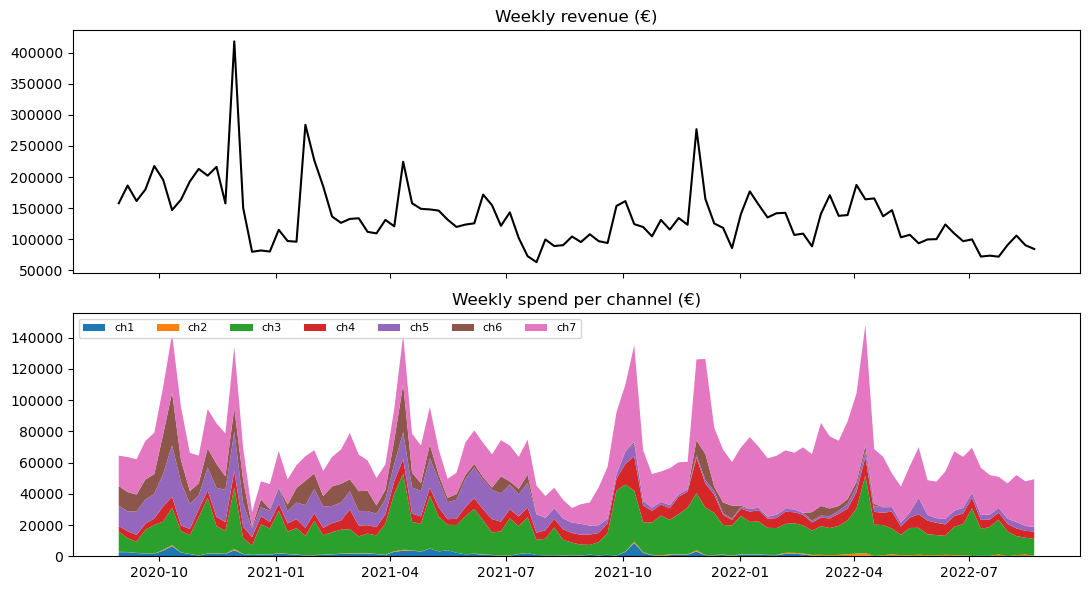

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(df.date, df.revenue, color="k")
ax[0].set_title("Weekly revenue (€)")
ax[1].stackplot(df.date, spend.T, labels=ch_names)
ax[1].set_title("Weekly spend per channel (€)")
ax[1].legend(ncol=7, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

In [5]:
# zoom into the revenue spikes
df["total_spend"] = df[channels].sum(axis=1)

def around(week_start, before=1, after=1):
    i = df.index[df["date"] == week_start][0]
    return df.loc[i - before : i + after, ["date", "revenue", "total_spend"]]

display(around("2020-11-29"))                      # Cyber Week 2020
display(around("2021-11-28"))                      # Cyber Week 2021
display(around("2021-01-24", before=1, after=3))   # January 2021

,date,revenue,total_spend
12,2020-11-22,157640.79,78692.54
13,2020-11-29,418186.38,134090.31
14,2020-12-06,150423.19,69475.15


,date,revenue,total_spend
64,2021-11-21,123340.71,60458.40
65,2021-11-28,276991.38,126138.75
66,2021-12-05,164983.21,126469.43


,date,revenue,total_spend
20,2021-01-17,96071.01,58399.84
21,2021-01-24,284010.24,64095.96
22,2021-01-31,226994.32,67991.39
23,2021-02-07,185245.11,54717.68
24,2021-02-14,136635.71,63656.59


What I take from this for the model:
- **Trend:** revenue goes down over the two years, so I add a linear trend.
- **Seasonality:** there is a yearly pattern (weak summers), so I add yearly Fourier terms.
- **Cyber Week:** the weeks starting 29 Nov 2020 and 28 Nov 2021 are 2 to 3 times a normal week. Spend also jumps in these weeks. Without an event term the model would give the ads credit for the whole spike, so I add a Cyber Week indicator.
- **January 2021:** three high weeks while spend stays flat. Nothing in the data explains this (maybe a promotion), so I leave it to the noise term.

## 2. Features

- **Scaling:** revenue and spend are both divided by the average weekly revenue. An average week is then 1.0, the priors are easy to set, and the channel coefficient is directly the ROAS (€ revenue per € spend). The sampler also works better with values around 1.
- **Trend:** `t` goes from 0 (first week) to 1 (last week). I keep it linear because with only 2 years a flexible trend could absorb ad effects.
- **Seasonality:** 2 pairs of yearly sin/cos waves (1 and 2 cycles per year), so 4 parameters. With only 2 yearly cycles, more pairs would start to fit noise.
- **Cyber Week:** 1 in the two Cyber Weeks, 0 otherwise. One shared effect for both years.

In [6]:
y_scale = df["revenue"].mean()
y = df["revenue"].values / y_scale      # scaled revenue (average week = 1)
X = spend / y_scale                     # same scale, so coefficients = ROAS

t = np.arange(T) / (T - 1)              # trend: 0 -> 1

day = df["date"].dt.dayofyear.values / 365.25          # position in the year (0 to 1)
fourier = np.column_stack([f(2 * np.pi * k * day) for k in (1, 2) for f in (np.sin, np.cos)])
fourier_names = ["sin1", "cos1", "sin2", "cos2"]

cyber_week = df["date"].isin(pd.to_datetime(["2020-11-29", "2021-11-28"])).astype(float).values

print(f"Average weekly revenue (scale): {y_scale:,.0f} €")
print("Fourier matrix:", fourier.shape, "| Cyber Week weeks:", int(cyber_week.sum()))

Average weekly revenue (scale): 136,490 €
Fourier matrix: (104, 4) | Cyber Week weeks: 2


## 3. Carry-over (adstock)

An ad in week $t$ also works in the following weeks. I use a geometric adstock with one decay rate $\alpha_c$ per channel:

$$
\text{adstock}_{c,t} = \sum_{l=0}^{L-1} w_{c,l}\,\text{spend}_{c,t-l}, \qquad w_{c,l} = \frac{\alpha_c^l}{\sum_{k=0}^{L-1}\alpha_c^k}
$$

- Each week keeps a share $\alpha$ of the previous week's effect. It needs only one parameter per channel and is easy to sample.
- $\alpha$ is per channel, because channels like TV and search ads can have very different delays.
- The weights sum to 1. Adstock only moves spend over time and does not change the total, so every € is counted once and the coefficient stays ROAS.
- The window is $L = 8$ weeks. Spend before the first week is unknown and treated as 0.

The plot shows how $\alpha$ changes the shape.

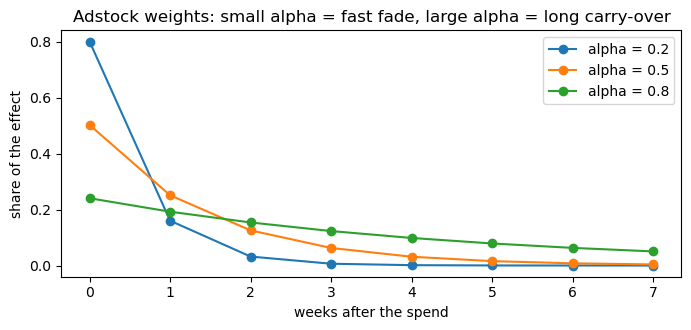

In [7]:
L_MAX = 8
lags = np.arange(L_MAX)

fig, ax = plt.subplots(figsize=(8, 3.2))
for a in (0.2, 0.5, 0.8):
    wa = a ** lags / (a ** lags).sum()
    ax.plot(lags, wa, marker="o", label=f"alpha = {a}")
ax.set_xlabel("weeks after the spend"); ax.set_ylabel("share of the effect")
ax.set_title("Adstock weights: small alpha = fast fade, large alpha = long carry-over"); ax.legend(); plt.show()

To compute adstock inside the model without loops, I build a lag array once: `X_lag[week, channel, l]` is the spend of that channel `l` weeks earlier. Adstock is then the weights times `X_lag`, summed over the last axis.

In [8]:
X_lag = np.zeros((T, C, L_MAX))          # weeks x channels x lags
for lag in range(L_MAX):
    X_lag[lag:, :, lag] = X[:T - lag]    # shift spend down by `lag` weeks, first weeks stay 0

assert np.allclose(X_lag[1:, :, 1], X[:-1])   # "1 week ago" in week n = "this week" in week n-1
X_lag.shape

(104, 7, 8)

## 4. Model and priors

$$
\text{revenue}_t = \underbrace{\beta_0 + \beta_{trend}\,t + \text{season}_t + \beta_{cw}\,\text{CyberWeek}_t}_{\text{baseline}} + \underbrace{\sum_{c=1}^{7} \text{ROAS}_c \cdot \text{adstock}_{c,t}}_{\text{media}} + \varepsilon_t, \qquad \varepsilon_t \sim \text{Normal}(0,\sigma)
$$

The model is linear and additive, so each channel's contribution in € can be read off directly. There are 22 unknowns: 7 decay rates, 7 ROAS values, intercept, trend, 4 seasonal weights, Cyber Week and $\sigma$.

| Parameter | Prior | Why these numbers (1.0 = an average week) |
|---|---|---|
| $\alpha$ (per channel) | Beta(1, 3) | Lives on [0, 1]. Mean 0.25, so 75% of the effect lands in the spend week. Highest density at 0, and P($\alpha$ > 0.5) = 12.5%, so long carry-over is still possible. |
| ROAS (per channel) | HalfNormal(1) | Ads cannot lower revenue. Spend is 51% of revenue, so even if ads made all revenue the average ROAS would be 1 / 0.51 ≈ 2. Scale 1 puts 95% of the mass below 2. The prior mean 0.8 implies a media share of about 40%. |
| intercept | Normal(0.5, 0.5) | About half of revenue without ads, in line with the 40% media share. sd 0.5 keeps 0 and 1 within one sd. |
| trend | Normal(0, 0.5) | `t` goes from 0 to 1, so this is the total change over 2 years. No direction assumed. Revenue falls from about 1.3 (first 8 weeks) to 0.6 (last 8), which is within 2 sd. |
| gamma (4 seasonal weights) | Normal(0, 0.3) | Each weight multiplies a wave between −1 and 1, so it is a swing in average weeks. Monthly mean revenue goes from 0.64 (July) to 1.22 (November), about ±0.3 around 1. A sin/cos pair then has a median swing of 0.35 and 95% below 0.73. |
| cyber_week | Normal(0, 1) | Extra revenue in that week. The Cyber Weeks are 3.1 and 2.0 vs about 1.0 to 1.2 around them, so the extra is 1 to 2 weeks, within 2 sd. A narrow prior would push the spike onto the ads. |
| $\sigma$ | HalfNormal(0.3) | The total sd of weekly revenue is 0.37, so noise cannot be much larger. Median 0.20, 95% below 0.59. |

All priors are weakly informative. They rule out impossible values but leave the data room to decide.

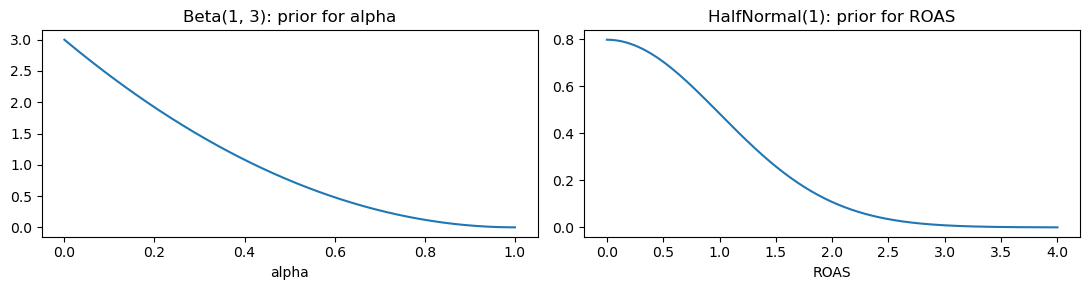

alpha prior mean: 0.25
ROAS prior median: 0.67 | P(ROAS < 2) = 95%


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
x = np.linspace(0, 1, 200)
ax[0].plot(x, stats.beta(1, 3).pdf(x)); ax[0].set_title("Beta(1, 3): prior for alpha"); ax[0].set_xlabel("alpha")
x = np.linspace(0, 4, 200)
ax[1].plot(x, stats.halfnorm(scale=1).pdf(x)); ax[1].set_title("HalfNormal(1): prior for ROAS"); ax[1].set_xlabel("ROAS")
plt.tight_layout(); plt.show()
print(f"alpha prior mean: {stats.beta(1, 3).mean():.2f}")
print(f"ROAS prior median: {stats.halfnorm(scale=1).median():.2f} | P(ROAS < 2) = {stats.halfnorm(scale=1).cdf(2):.0%}")

The model is wrapped in a function so I can refit it on only the first 88 weeks later (holdout test in step 8). `mu` is computed for all 104 weeks, but only the first `n_train` weeks are compared with the data.

In [10]:
def build_mmm(n_train=T):
    coords = {"channel": ch_names, "fourier": fourier_names, "week": np.arange(T)}
    with pm.Model(coords=coords) as model:

        # priors
        alpha     = pm.Beta("alpha", alpha=1, beta=3, dims="channel")      # decay rate per channel
        roas      = pm.HalfNormal("roas", sigma=1, dims="channel")         # € revenue per € spend
        intercept = pm.Normal("intercept", mu=0.5, sigma=0.5)
        trend     = pm.Normal("trend", mu=0, sigma=0.5)
        gamma     = pm.Normal("gamma", mu=0, sigma=0.3, dims="fourier")
        beta_cw   = pm.Normal("cyber_week", mu=0, sigma=1)
        sigma     = pm.HalfNormal("sigma", sigma=0.3)

        # adstock: (7, 8) weight matrix, each row normalised to sum to 1
        w = alpha[:, None] ** lags[None, :]
        w = w / w.sum(axis=1, keepdims=True)
        adstock = (X_lag * w[None, :, :]).sum(axis=-1)          # (weeks, 7)

        # expected revenue = baseline + media
        contribution = pm.Deterministic("contribution", adstock * roas, dims=("week", "channel"))
        baseline = pm.Deterministic(
            "baseline", intercept + trend * t + fourier @ gamma + beta_cw * cyber_week, dims="week")
        mu = pm.Deterministic("mu", baseline + contribution.sum(axis=1), dims="week")

        # likelihood
        pm.Normal("revenue", mu=mu[:n_train], sigma=sigma, observed=y[:n_train])
    return model

mmm = build_mmm()
print("Unknowns:", [rv.name for rv in mmm.free_RVs])

Unknowns: ['alpha', 'roas', 'intercept', 'trend', 'gamma', 'cyber_week', 'sigma']


## 5. Prior predictive check

Before fitting, I simulate revenue from the priors only. This checks if my assumptions give a believable world. The band should cover the real data without being absurdly wide.

In [11]:
with mmm:
    prior = pm.sample_prior_predictive(draws=1000, random_seed=SEED)

def flat(group, var):
    # merge (chain, draw) into one sample axis
    a = group[var].values
    return a.reshape(-1, *a.shape[2:])

Sampling: [alpha, cyber_week, gamma, intercept, revenue, roas, sigma, trend]


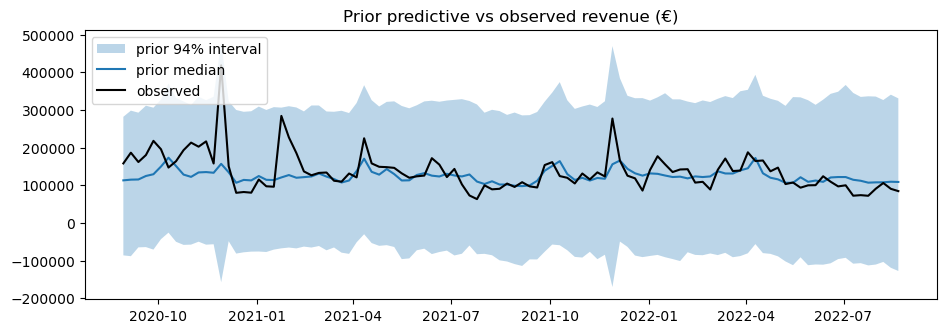

Prior: median share of revenue driven by media = 0.4


In [12]:
prior_rev = flat(prior.prior_predictive, "revenue") * y_scale
lo, hi = np.percentile(prior_rev, [3, 97], axis=0)       # central 94% band
plt.fill_between(df.date, lo, hi, alpha=0.3, label="prior 94% interval")
plt.plot(df.date, np.median(prior_rev, 0), label="prior median")
plt.plot(df.date, df.revenue, "k", label="observed")
plt.title("Prior predictive vs observed revenue (€)"); plt.legend(); plt.show()

prior_media_share = flat(prior.prior, "contribution").sum((1, 2)) / flat(prior.prior, "mu").sum(1)
print("Prior: median share of revenue driven by media =", np.median(prior_media_share).round(2))

- The prior median is at a realistic level and the band covers the observed revenue.
- The band is wide, as expected before seeing data. It also allows some negative revenue, which is a weakness of the Normal likelihood.
- The implied media share is about 40%, so the priors do not push towards "ads do everything" or "ads do nothing".

## 6. Sampling and diagnostics

I run NUTS with 4 chains, 1000 tuning steps (discarded) and 1000 kept draws each, so 4000 posterior samples. `target_accept=0.95` makes the steps smaller, which lowers the risk of divergences. After that I draw posterior predictive samples for the fit check in step 8.

In [13]:
with mmm:
    idata = pm.sample(draws=1000, tune=1000, chains=4, cores=CORES, target_accept=0.95,
                      random_seed=SEED, progressbar=False)
    pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=SEED, progressbar=False)
post = idata.posterior

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, roas, intercept, trend, gamma, cyber_week, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.
Sampling: [revenue]


Before I trust any result I check three things: divergences should be 0, r_hat should be below 1.01 (the 4 chains agree), and ESS should be in the hundreds or more.

In [14]:
main_vars = ["alpha", "roas", "intercept", "trend", "cyber_week", "sigma"]
print("Divergences:", int(idata.sample_stats["diverging"].sum()))
az.summary(idata, var_names=main_vars)

Divergences: 0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[ch1],0.260,0.201,0.000,0.639,0.003,0.003,3430.0,1912.0,1.0
alpha[ch2],0.254,0.195,0.000,0.617,0.003,0.003,3983.0,2285.0,1.0
alpha[ch3],0.208,0.176,0.000,0.532,0.003,0.003,2794.0,1587.0,1.0
alpha[ch4],0.239,0.192,0.000,0.597,0.003,0.003,3788.0,1895.0,1.0
alpha[ch5],0.190,0.149,0.000,0.457,0.002,0.002,3556.0,1894.0,1.0
alpha[ch6],0.227,0.179,0.000,0.551,0.003,0.003,3640.0,2147.0,1.0
alpha[ch7],0.251,0.182,0.000,0.579,0.003,0.003,3379.0,1413.0,1.0
roas[ch1],0.552,0.468,0.000,1.417,0.007,0.008,2707.0,1665.0,1.0
roas[ch2],0.815,0.600,0.000,1.902,0.011,0.010,1916.0,1031.0,1.0
roas[ch3],0.638,0.386,0.001,1.288,0.008,0.005,1889.0,1296.0,1.0


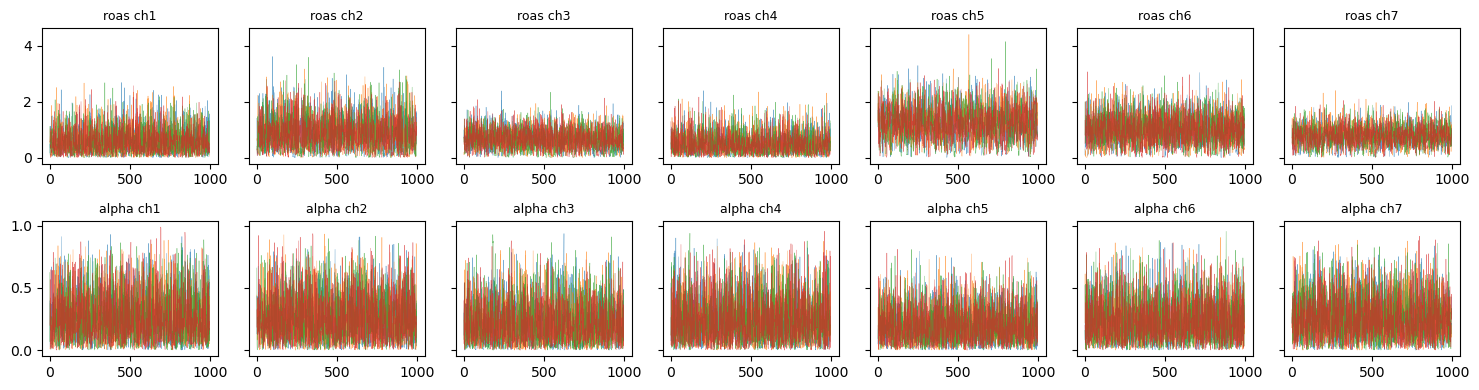

In [15]:
# trace plots: the 4 chains should overlap with no drift
fig, axes = plt.subplots(2, C, figsize=(15, 4), sharey="row")
for row, var in enumerate(["roas", "alpha"]):
    a = post[var].values                      # (chain, draw, channel)
    for c in range(C):
        for chain in range(a.shape[0]):
            axes[row, c].plot(a[chain, :, c], lw=0.3, alpha=0.7)
        axes[row, c].set_title(f"{var} {ch_names[c]}", fontsize=9)
plt.tight_layout(); plt.show()

- 0 divergences, r_hat = 1.00 for all parameters and ESS above 1000 everywhere. The sampler converged.
- The chains overlap in the trace plots, which is the visual version of r_hat ≈ 1.
- Every $\alpha$ has a wide interval (about 0 to 0.6). The data cannot pin down the decay rates well (see step 7).

## 7. Prior vs posterior

Here I compare prior and posterior for ROAS and $\alpha$. If the posterior is narrower, the data was informative. If it is shifted, the data disagreed with the prior. If it looks like the prior, the data said little about it. The `sd ratio` is posterior sd / prior sd.

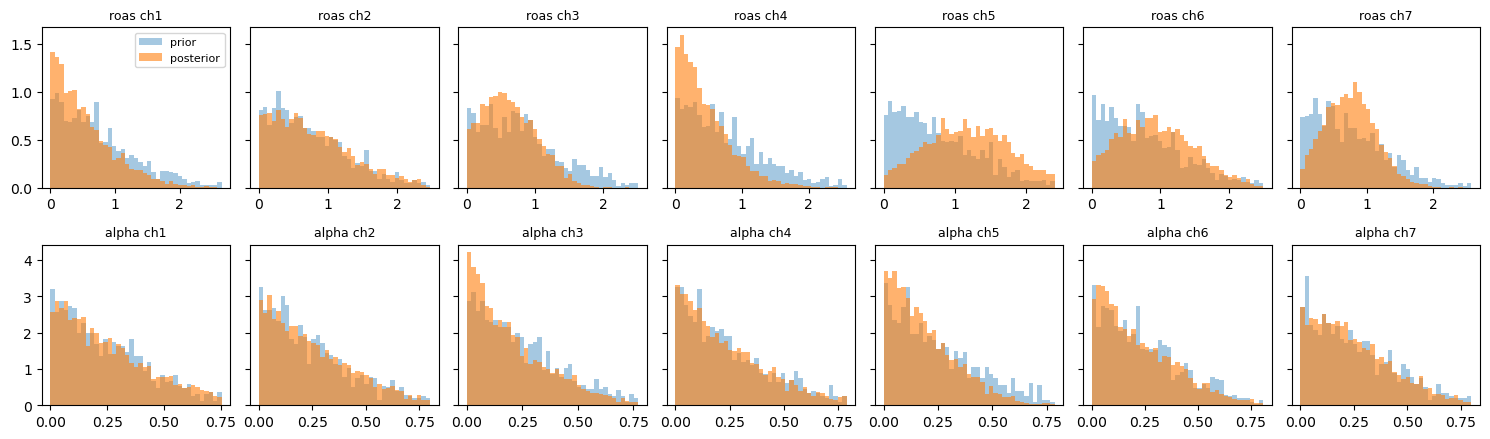

,roas_prior_mean,roas_post_mean,roas_post_sd / prior_sd,alpha_post_sd / prior_sd
ch1,0.77,0.55,0.77,1.06
ch2,0.77,0.81,1.03,0.98
ch3,0.82,0.64,0.65,0.92
ch4,0.77,0.47,0.65,0.97
ch5,0.78,1.22,1.05,0.76
ch6,0.80,0.97,0.91,0.94
ch7,0.78,0.76,0.66,0.93


In [16]:
fig, axes = plt.subplots(2, C, figsize=(15, 4.5), sharey="row")
for row, var in enumerate(["roas", "alpha"]):
    pr, po = flat(prior.prior, var), flat(post, var)
    for c in range(C):
        ax = axes[row, c]
        bins = np.linspace(0, np.percentile(pr[:, c], 99), 40)
        ax.hist(pr[:, c], bins, density=True, alpha=0.4, label="prior")
        ax.hist(po[:, c], bins, density=True, alpha=0.6, label="posterior")
        ax.set_title(f"{var} {ch_names[c]}", fontsize=9)
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

learn = pd.DataFrame({
    "roas_prior_mean": flat(prior.prior, "roas").mean(0),
    "roas_post_mean": flat(post, "roas").mean(0),
    "roas_post_sd / prior_sd": flat(post, "roas").std(0) / flat(prior.prior, "roas").std(0),
    "alpha_post_sd / prior_sd": flat(post, "alpha").std(0) / flat(prior.prior, "alpha").std(0),
}, index=ch_names).round(2)
learn

- **ch3, ch4, ch7** (large and varying budgets): the ROAS posterior is about 35% narrower than the prior. ch3 and ch4 also move down.
- **ch5:** the mean moves up from 0.8 to 1.2, so the data says it works better than the prior assumed. The width stays the same.
- **ch1:** moves down and gets a bit narrower, but its budget is small.
- **ch2:** posterior ≈ prior. With 0.5% of the budget the data says almost nothing about it.
- **$\alpha$:** stays close to the prior for all channels. The timing of the effect is much harder to learn from 104 weeks than its size.

## 8. Model performance

**(a) In-sample fit.** R² (share of variation explained) and MAPE (average % error per week) use the expected revenue `mu`. Coverage uses the posterior predictive (`mu` + noise): in a well calibrated model about 94% of weeks fall inside the 94% band.

In-sample  R² = 0.64 | MAPE = 17.4% | 94% interval coverage = 97%


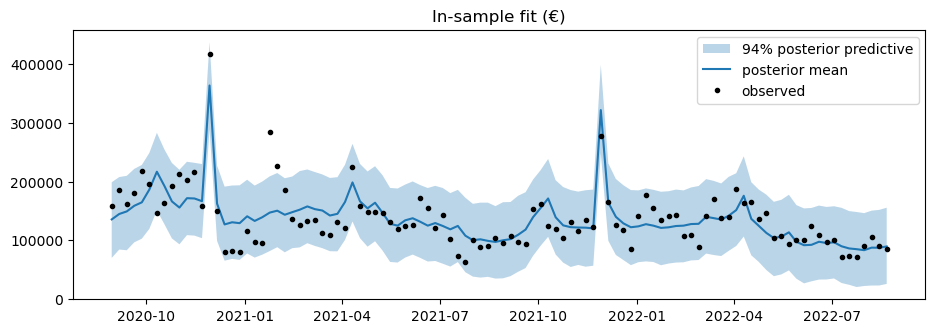

In [17]:
mu_draws = flat(post, "mu") * y_scale                          # expected revenue in € (samples x weeks)
ppc = flat(idata.posterior_predictive, "revenue") * y_scale    # with noise
pred = mu_draws.mean(0)
obs = df["revenue"].values

def r2(o, p):   return 1 - ((o - p) ** 2).sum() / ((o - o.mean()) ** 2).sum()
def mape(o, p): return np.mean(np.abs(o - p) / o)

lo, hi = np.percentile(ppc, [3, 97], axis=0)
coverage = np.mean((obs >= lo) & (obs <= hi))
print(f"In-sample  R² = {r2(obs, pred):.2f} | MAPE = {mape(obs, pred):.1%} | 94% interval coverage = {coverage:.0%}")

plt.fill_between(df.date, lo, hi, alpha=0.3, label="94% posterior predictive")
plt.plot(df.date, pred, label="posterior mean")
plt.plot(df.date, obs, "k.", label="observed")
plt.title("In-sample fit (€)"); plt.legend(); plt.show()

- The model follows the trend and both Cyber Weeks. It explains about 64% of the variation, with a typical weekly error of about 17%.
- Coverage is 97% for a 94% band, so the band is a little too wide (conservative).
- Main misses: late January 2021 (no driver in the data), the shared Cyber Week effect (too low for 2020, too high for 2021) and the first weeks (spend before the data start is missing from the adstock).

**(b) Holdout test.** In-sample fit is optimistic, so I hide the last 16 weeks, fit on the first 88 and predict the hidden weeks with their known spend. I use the last weeks and not random weeks, so the model cannot look at the future.

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, roas, intercept, trend, gamma, cyber_week, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 7 seconds.


Holdout MAPE: model = 11.5% | naive (last-16-week mean) = 52.4%
Holdout 94% interval coverage = 100%


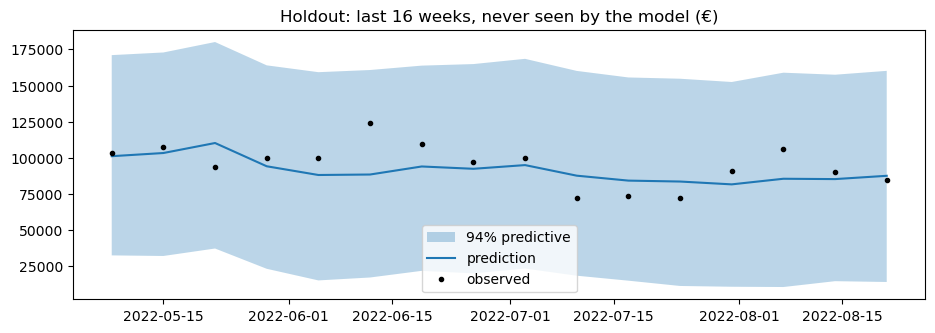

In [18]:
N_TRAIN = 88
with build_mmm(n_train=N_TRAIN):
    idata_ho = pm.sample(draws=1000, tune=1000, chains=4, cores=CORES, target_accept=0.95,
                         random_seed=SEED, progressbar=False)

mu_ho = flat(idata_ho.posterior, "mu")[:, N_TRAIN:] * y_scale   # predictions for the 16 hidden weeks
sig_ho = flat(idata_ho.posterior, "sigma")[:, None] * y_scale
ppc_ho = rng.normal(mu_ho, sig_ho)                              # add observation noise
obs_te, pred_te = obs[N_TRAIN:], mu_ho.mean(0)
lo_te, hi_te = np.percentile(ppc_ho, [3, 97], axis=0)
naive = np.full_like(obs_te, obs[N_TRAIN - 16:N_TRAIN].mean())  # mean of the last 16 training weeks

print(f"Holdout MAPE: model = {mape(obs_te, pred_te):.1%} | naive (last-16-week mean) = {mape(obs_te, naive):.1%}")
print(f"Holdout 94% interval coverage = {np.mean((obs_te >= lo_te) & (obs_te <= hi_te)):.0%}")

d = df.date[N_TRAIN:]
plt.fill_between(d, lo_te, hi_te, alpha=0.3, label="94% predictive")
plt.plot(d, pred_te, label="prediction"); plt.plot(d, obs_te, "k.", label="observed")
plt.title("Holdout: last 16 weeks, never seen by the model (€)"); plt.legend(); plt.show()

The naive forecast is easy to beat, because the test weeks (May to August 2022) are a seasonal low. So I add two stronger benchmarks on the same 16 weeks:
1. **Seasonal naive:** each week equals the same week one year earlier.
2. **No-media model:** the same model without the 7 channels (only trend, seasonality and Cyber Week). This shows if the channels add predictive value. Its intercept prior is centred at 1, because here the baseline has to carry all revenue.

In [19]:
seasonal_naive = obs[N_TRAIN - 52 : T - 52]     # same calendar weeks one year earlier

def build_no_media(n_train=T):
    coords = {"fourier": fourier_names, "week": np.arange(T)}
    with pm.Model(coords=coords) as model:
        intercept = pm.Normal("intercept", mu=1.0, sigma=0.5)
        trend     = pm.Normal("trend", mu=0, sigma=0.5)
        gamma     = pm.Normal("gamma", mu=0, sigma=0.3, dims="fourier")
        beta_cw   = pm.Normal("cyber_week", mu=0, sigma=1)
        sigma     = pm.HalfNormal("sigma", sigma=0.3)
        mu = pm.Deterministic("mu", intercept + trend * t + fourier @ gamma + beta_cw * cyber_week, dims="week")
        pm.Normal("revenue", mu=mu[:n_train], sigma=sigma, observed=y[:n_train])
    return model

with build_no_media(n_train=N_TRAIN):
    idata_nm = pm.sample(draws=1000, tune=1000, chains=4, cores=CORES, target_accept=0.95,
                         random_seed=SEED, progressbar=False)

rng_nm = np.random.default_rng(SEED)            # separate generator, so other results do not change
mu_nm = flat(idata_nm.posterior, "mu")[:, N_TRAIN:] * y_scale
sig_nm = flat(idata_nm.posterior, "sigma")[:, None] * y_scale
lo_nm, hi_nm = np.percentile(rng_nm.normal(mu_nm, sig_nm), [3, 97], axis=0)

cov_full = np.mean((obs_te >= lo_te) & (obs_te <= hi_te))
cov_nm = np.mean((obs_te >= lo_nm) & (obs_te <= hi_nm))
bench = pd.DataFrame({
    "holdout MAPE": [f"{mape(obs_te, pred_te):.1%}", f"{mape(obs_te, mu_nm.mean(0)):.1%}",
                     f"{mape(obs_te, seasonal_naive):.1%}", f"{mape(obs_te, naive):.1%}"],
    "94% interval coverage": [f"{cov_full:.0%}", f"{cov_nm:.0%}", "-", "-"],
}, index=["full model (baseline + 7 channels)", "no-media model (baseline only)",
          "seasonal naive (same week last year)", "naive (last-16-week mean)"])
print(bench.to_string())
print(f"\nAdding the 7 channels changes the holdout error from {mape(obs_te, mu_nm.mean(0)):.1%} to {mape(obs_te, pred_te):.1%}.")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, trend, gamma, cyber_week, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


                                     holdout MAPE 94% interval coverage
full model (baseline + 7 channels)          11.5%                  100%
no-media model (baseline only)              13.5%                  100%
seasonal naive (same week last year)        24.7%                     -
naive (last-16-week mean)                   52.4%                     -

Adding the 7 channels changes the holdout error from 13.5% to 11.5%.


- The full model has about half the error of the seasonal naive forecast, so it learns more than "summer is quiet".
- The no-media model is already good. Most of what is predictable comes from trend, season and Cyber Week. The channels lower the error by about 2 points, which is a real but modest gain on only 16 weeks.
- All 16 hidden weeks fall inside the 94% band, so the uncertainty is on the safe side.

## 9. Channel insights

**Carry-over per channel.** `effect_after_week0_%` is the share of the effect that comes after the week of the spend ($1 - w_0$). Since $\alpha$ barely moved from the prior, I read this as "short carry-over", not as exact timing per channel.

In [20]:
a_draws = flat(post, "alpha")
later = 1 - 1 / (a_draws[:, :, None] ** lags).sum(-1)       # 1 - w0 for every sample
carry = pd.DataFrame({
    "alpha_mean": a_draws.mean(0),
    "alpha_94%_low": np.percentile(a_draws, 3, 0),
    "alpha_94%_high": np.percentile(a_draws, 97, 0),
    "effect_after_week0_%": 100 * later.mean(0),
}, index=ch_names).round(2)
carry

,alpha_mean,alpha_94%_low,alpha_94%_high,effect_after_week0_%
ch1,0.26,0.01,0.71,25.75
ch2,0.25,0.01,0.69,25.22
ch3,0.21,0.01,0.62,20.73
ch4,0.24,0.01,0.69,23.72
ch5,0.19,0.01,0.53,18.93
ch6,0.23,0.01,0.63,22.62
ch7,0.25,0.01,0.66,24.97


**Revenue decomposition.** The model is additive, so each week splits into baseline + contribution of each channel. The media share is computed for every posterior sample, so it gets an interval too.

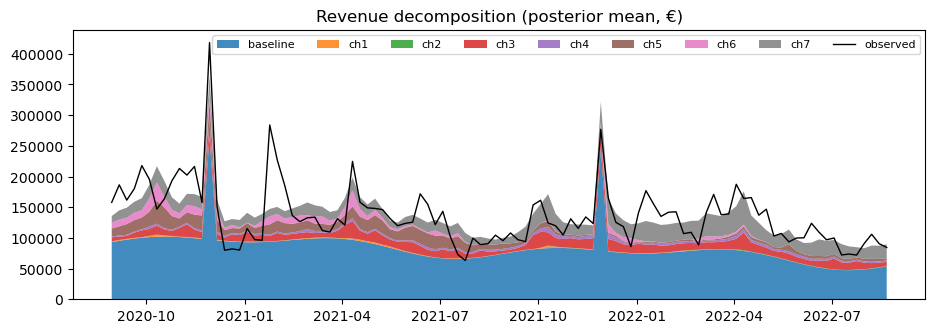

Share of revenue driven by paid media: 39% (94% interval: 24% to 55%)


In [21]:
contrib = flat(post, "contribution") * y_scale              # (samples, weeks, channels) in €
base = flat(post, "baseline").mean(0) * y_scale
contrib_mean = contrib.mean(0)

plt.stackplot(df.date, base, *contrib_mean.T, labels=["baseline"] + ch_names, alpha=0.85)
plt.plot(df.date, obs, "k", lw=1, label="observed")
plt.title("Revenue decomposition (posterior mean, €)"); plt.legend(ncol=9, fontsize=8, loc="upper right")
plt.show()

total_contrib = contrib.sum(1)                              # (samples, channels): € over 2 years
media_share = total_contrib.sum(1) / mu_draws.sum(1)
print(f"Share of revenue driven by paid media: {media_share.mean():.0%} "
      f"(94% interval: {np.percentile(media_share, 3):.0%} to {np.percentile(media_share, 97):.0%})")

Paid media drives about 39% of revenue (94% interval 24% to 55%). The Cyber Week peaks are in the baseline and not in the ads, so the event term works as intended.

**What is in the baseline?** Trend and seasonality from the posterior means, in € per week.

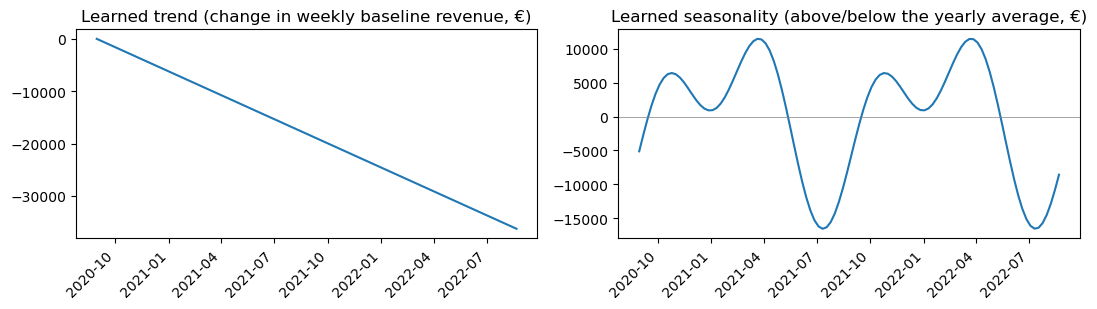

In [22]:
trend_c = flat(post, "trend").mean() * t * y_scale
season_c = (fourier @ flat(post, "gamma").mean(0)) * y_scale

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(df.date, trend_c); ax[0].set_title("Learned trend (change in weekly baseline revenue, €)")
ax[1].plot(df.date, season_c); ax[1].axhline(0, color="grey", lw=0.5)
ax[1].set_title("Learned seasonality (above/below the yearly average, €)")
for a in ax:
    plt.setp(a.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

- The weekly baseline falls by about 36k € over the two years (about 26% of an average week).
- Seasonality has a summer low (around July) and two peaks, a bigger one in spring and a smaller one in autumn. Ad spend also rises in spring and autumn, so without these terms the ads would get credit for the seasonal rise.

**Share of spend vs share of media revenue.** If a channel's share of media revenue is higher than its share of spend, its ROAS is above the media average.

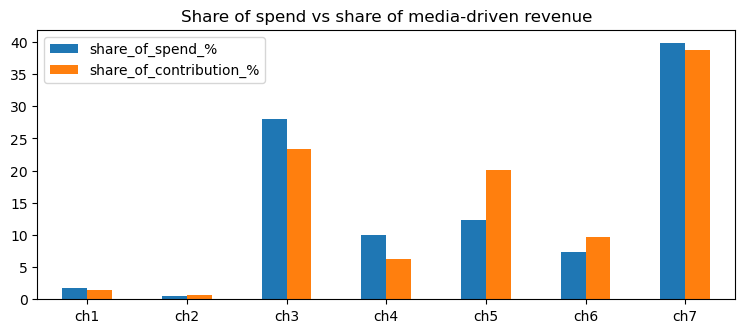

,share_of_spend_%,share_of_contribution_%
ch1,1.8,1.4
ch2,0.5,0.6
ch3,28.1,23.4
ch4,10.0,6.2
ch5,12.4,20.1
ch6,7.3,9.7
ch7,39.9,38.7


In [23]:
share = pd.DataFrame({
    "share_of_spend_%": 100 * spend.sum(0) / spend.sum(),
    "share_of_contribution_%": 100 * (total_contrib / total_contrib.sum(1, keepdims=True)).mean(0),
}, index=ch_names).round(1)
share.plot.bar(rot=0, title="Share of spend vs share of media-driven revenue", figsize=(9, 3.5)); plt.show()
share

- ch5 and ch6 bring more than their budget share (ch5: 12% of spend, 20% of media revenue).
- ch3 and ch4 bring less than their budget share. ch7, the largest budget, is about at par.
- ch1 and ch2 are too small to judge.

This only compares channels with each other. Above average does not mean profitable, because the average media ROAS is below 1. Step 10 looks at ROAS directly.

## 10. ROI per channel

$$
\text{ROAS}_c = \frac{\text{revenue driven by channel } c}{\text{spend on channel } c}, \qquad \text{ROI}_c = \text{ROAS}_c - 1
$$

For each of the 4000 posterior samples I sum the channel's contribution over all weeks and divide by its total spend. This gives a full distribution of ROAS per channel. It is almost the same as the `roas` parameter; the small difference comes from spend in the last weeks whose carry-over falls outside the data.

- `P(ROAS > 1)`: probability that the channel at least pays back its spend in revenue.
- `P(best channel)`: share of samples where the channel has the highest ROAS.

This is revenue-based. With a product margin $m$, a channel only breaks even if $m \times \text{ROAS} > 1$.

In [24]:
roas_draws = total_contrib / spend.sum(0)                                  # (samples, channels)
best = np.bincount(roas_draws.argmax(1), minlength=C) / len(roas_draws)

roi_table = pd.DataFrame({
    "spend_€": spend.sum(0).round(0),
    "ROAS_mean": roas_draws.mean(0),
    "ROAS_94%_low": np.percentile(roas_draws, 3, 0),
    "ROAS_94%_high": np.percentile(roas_draws, 97, 0),
    "ROI_mean_%": 100 * (roas_draws.mean(0) - 1),
    "P(ROAS > 1)": (roas_draws > 1).mean(0),
    "P(best channel)": best,
}, index=ch_names).round(2).sort_values("ROAS_mean", ascending=False)
roi_table

,spend_€,ROAS_mean,ROAS_94%_low,ROAS_94%_high,ROI_mean_%,P(ROAS > 1),P(best channel)
ch5,891864.0,1.22,0.18,2.43,21.90,0.61,0.41
ch6,526625.0,0.97,0.10,2.09,-3.48,0.44,0.22
ch2,35739.0,0.81,0.04,2.17,-19.13,0.33,0.14
ch7,2880942.0,0.76,0.11,1.50,-24.06,0.26,0.08
ch3,2028747.0,0.64,0.05,1.42,-36.29,0.18,0.05
ch1,129543.0,0.55,0.02,1.66,-44.84,0.17,0.06
ch4,719174.0,0.47,0.02,1.40,-53.45,0.10,0.03


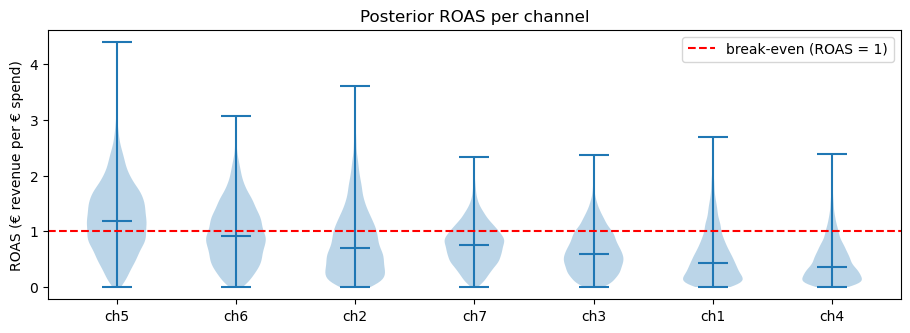

In [25]:
order = [ch_names.index(c) for c in roi_table.index]       # best first
plt.violinplot([roas_draws[:, i] for i in order], showmedians=True)
plt.xticks(range(1, C + 1), roi_table.index)
plt.axhline(1, color="r", ls="--", label="break-even (ROAS = 1)")
plt.ylabel("ROAS (€ revenue per € spend)"); plt.title("Posterior ROAS per channel"); plt.legend(); plt.show()

- **ch5 is the best channel:** ROAS ≈ 1.22 (ROI ≈ +22%), P(ROAS > 1) = 61%, and it is the best channel in 41% of samples, more than any other channel.
- ch6 is second with ROAS ≈ 0.97 (about break-even). ch4 is the weakest (≈ 0.47).
- The intervals overlap a lot (ch5: 0.18 to 2.43), so the ranking is a probability and not a certainty. ch5 and ch6 are also the most correlated pair in spend.
- Most channels have a mean ROAS below 1 in revenue terms, before margins.

## 11. Summary

**Summary**
- Carry-over is short (about 19 to 26% of the effect comes after the spend week), but the decay rates are not well identified.
- Paid media drives about 39% of revenue. The rest is baseline: a declining trend, seasonality and Cyber Week.
- The model converged cleanly. In-sample R² = 0.64, MAPE = 17%. On the 16 hidden weeks MAPE = 11.5%, better than seasonal naive (24.7%) and the no-media model (13.5%).
- ch5 has the best ROAS (≈ 1.22, P(ROAS > 1) = 61%), ch6 is second, ch4 and ch3 return the least per €. ch1 and ch2 are too small to judge.